In [1]:
import requests
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# NCBI-dən insan TP53 zülal ardıcıllığını alırıq
url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"

params = {
    "db": "protein",
    "id": "NP_000537.3",
    "rettype": "fasta",
    "retmode": "text"
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

fasta_text = response.text.strip()

# FASTA başlığını və ardıcıllığı ayırırıq
lines = fasta_text.splitlines()
header = lines[0]
protein_sequence = "".join(lines[1:]).replace(" ", "")

print("NCBI-dən alınan məlumat:")
print(header)
print("\nZülalın uzunluğu:", len(protein_sequence), "amin turşusu")
print("İlk 60 amin turşusu:")
print(protein_sequence[:60])

NCBI-dən alınan məlumat:
>NP_000537.3 cellular tumor antigen p53 isoform a [Homo sapiens]

Zülalın uzunluğu: 393 amin turşusu
İlk 60 amin turşusu:
MEEPQSDPSVEPPLSQETFSDLWKLLPENNVLSPLPSQAMDDLMLSPDDIEQWFTEDPGP


In [2]:
position = 175  # Bioloji mövqe: 1-dən başlayır

reference_aa = protein_sequence[position - 1]

start = position - 8
end = position + 7

window = protein_sequence[start:end]

print("Zülal mövqeyi:", position)
print("NCBI ardıcıllığında bu mövqedə:", reference_aa)
print("Mövqenin ətrafındakı ardıcıllıq:", window)

# Hər amin turşusunun mövqeyini göstəririk
for i, aa in enumerate(window, start=start + 1):
    marker = "<-- 175-ci mövqe" if i == position else ""
    print(f"{i:>3}: {aa} {marker}")

Zülal mövqeyi: 175
NCBI ardıcıllığında bu mövqedə: R
Mövqenin ətrafındakı ardıcıllıq: HMTEVVRRCPHHERC
168: H 
169: M 
170: T 
171: E 
172: V 
173: V 
174: R 
175: R <-- 175-ci mövqe
176: C 
177: P 
178: H 
179: H 
180: E 
181: R 
182: C 


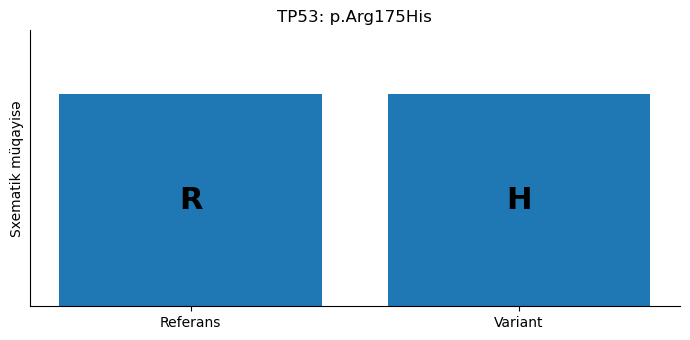

Referans: p.Arg175
Variant:  p.His175


In [3]:
import matplotlib.pyplot as plt

position = 175

# Zülalın real RefSeq ardıcıllığında mövqeyi yoxlayırıq
reference_aa = protein_sequence[position - 1]

if reference_aa != "R":
    raise ValueError(
        f"175-ci mövqedə R deyil, {reference_aa} tapıldı. "
        "RefSeq versiyasını yoxlayın."
    )

variant_aa = "H"

labels = ["Referans", "Variant"]
amino_acids = [reference_aa, variant_aa]

fig, ax = plt.subplots(figsize=(7, 3.5))

bars = ax.bar(labels, [1, 1])

for bar, aa in zip(bars, amino_acids):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        0.5,
        aa,
        ha="center",
        va="center",
        fontsize=22,
        fontweight="bold"
    )

ax.set_ylim(0, 1.3)
ax.set_ylabel("Sxematik müqayisə")
ax.set_title("TP53: p.Arg175His")
ax.set_yticks([])
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

print(f"Referans: p.Arg175")
print(f"Variant:  p.His175")

In [4]:
# TP53 p.Arg175His üçün ClinVar-da göstərilən kodonlar
reference_codon = "CGC"
variant_codon = "CAC"

# Sadə nümayiş üçün genetik kod lüğəti
genetic_code = {
    "CGC": "Arginine (Arg, R)",
    "CAC": "Histidine (His, H)"
}

print("Referans kodon:", reference_codon)
print("Kodlaşdırdığı amin turşusu:", genetic_code[reference_codon])

print("\nVariant kodonu:", variant_codon)
print("Kodlaşdırdığı amin turşusu:", genetic_code[variant_codon])

print("\nNukleotid dəyişikliyi:",
      reference_codon[1], "→", variant_codon[1])

Referans kodon: CGC
Kodlaşdırdığı amin turşusu: Arginine (Arg, R)

Variant kodonu: CAC
Kodlaşdırdığı amin turşusu: Histidine (His, H)

Nukleotid dəyişikliyi: G → A


In [5]:
import requests

base_url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/"

# ClinVar bazasında TP53 Arg175His variantını axtarırıq
search_params = {
    "db": "clinvar",
    "term": '"NM_000546.6"[Variant Name]',
    "retmode": "json",
    "retmax": 10
}

search_response = requests.get(
    base_url + "esearch.fcgi",
    params=search_params,
    timeout=30
)
search_response.raise_for_status()

search_data = search_response.json()
variant_ids = search_data["esearchresult"]["idlist"]

print("Tapılan ClinVar qeyd ID-ləri:", variant_ids)

if variant_ids:
    summary_params = {
        "db": "clinvar",
        "id": ",".join(variant_ids),
        "retmode": "json"
    }

    summary_response = requests.get(
        base_url + "esummary.fcgi",
        params=summary_params,
        timeout=30
    )
    summary_response.raise_for_status()

    summary = summary_response.json()["result"]

    for variant_id in variant_ids:
        record = summary.get(variant_id, {})
        print("\nQeyd ID-si:", variant_id)
        print("Başlıq:", record.get("title", "Məlumat yoxdur"))
        print("Əlavə məlumat:", record.get("obj_type", ""))
else:
    print(
        "Bu sorğu ilə uyğun qeyd tapılmadı. "
        "ClinVar-da birbaşa axtarış edin."
    )

Tapılan ClinVar qeyd ID-ləri: ['4982772', '4933289', '4933288', '4933287', '4933286', '4933285', '4933284', '4933283', '4933282', '4933281']

Qeyd ID-si: 4982772
Başlıq: NM_000546.6(TP53):c.97-35C>A
Əlavə məlumat: single nucleotide variant

Qeyd ID-si: 4933289
Başlıq: NM_000546.6(TP53):c.-29G>A
Əlavə məlumat: single nucleotide variant

Qeyd ID-si: 4933288
Başlıq: NM_000546.6(TP53):c.-29+3_-29+5delinsTAC
Əlavə məlumat: Indel

Qeyd ID-si: 4933287
Başlıq: NM_000546.6(TP53):c.106C>G (p.Pro36Ala)
Əlavə məlumat: single nucleotide variant

Qeyd ID-si: 4933286
Başlıq: NM_000546.6(TP53):c.106_108delinsGCA (p.Pro36Ala)
Əlavə məlumat: Indel

Qeyd ID-si: 4933285
Başlıq: NM_000546.6(TP53):c.182A>C (p.Asp61Ala)
Əlavə məlumat: single nucleotide variant

Qeyd ID-si: 4933284
Başlıq: NM_000546.6(TP53):c.328delinsTTGCATTCTGG (p.Arg110fs)
Əlavə məlumat: Indel

Qeyd ID-si: 4933283
Başlıq: NM_000546.6(TP53):c.532_535del (p.His178fs)
Əlavə məlumat: Deletion

Qeyd ID-si: 4933282
Başlıq: NM_000546.6(TP53):c.72

In [6]:
import requests
from urllib.parse import quote

hgvs = "NM_000546.6:c.524G>A"

url = (
    "https://rest.ensembl.org/vep/human/hgvs/"
    + quote(hgvs, safe="")
)

headers = {
    "Accept": "application/json"
}

response = requests.get(
    url,
    headers=headers,
    timeout=60
)

print("HTTP status:", response.status_code)

response.raise_for_status()
vep_data = response.json()

print("VEP nəticələrinin sayı:", len(vep_data))
print("Sorğu uğurla tamamlandı.")

HTTP status: 200
VEP nəticələrinin sayı: 1
Sorğu uğurla tamamlandı.


In [7]:
for variant in vep_data:
    print("\nDaxil edilmiş variant:", variant.get("input"))
    print("Genomik mövqe:", variant.get("seq_region_name"),
          variant.get("start"))
    print("Allellər:", variant.get("allele_string"))

    for consequence in variant.get(
        "transcript_consequences", []
    ):
        print("\nGen:", consequence.get("gene_symbol"))
        print("Transkript:", consequence.get("transcript_id"))
        print("Consequence:",
              ", ".join(
                  consequence.get("consequence_terms", [])
              ))
        print("IMPACT:", consequence.get("impact"))
        print("HGVSc:", consequence.get("hgvsc"))
        print("HGVSp:", consequence.get("hgvsp"))
        print("Zülal mövqeyi:",
              consequence.get("protein_start"))


Daxil edilmiş variant: NM_000546.6:c.524G>A
Genomik mövqe: 17 7675088
Allellər: G/A

Gen: TP53
Transkript: ENST00000269305
Consequence: missense_variant
IMPACT: MODERATE
HGVSc: None
HGVSp: None
Zülal mövqeyi: 175

Gen: TP53
Transkript: ENST00000359597
Consequence: missense_variant
IMPACT: MODERATE
HGVSc: None
HGVSp: None
Zülal mövqeyi: 175

Gen: TP53
Transkript: ENST00000413465
Consequence: missense_variant
IMPACT: MODERATE
HGVSc: None
HGVSp: None
Zülal mövqeyi: 175

Gen: TP53
Transkript: ENST00000420246
Consequence: missense_variant
IMPACT: MODERATE
HGVSc: None
HGVSp: None
Zülal mövqeyi: 175

Gen: TP53
Transkript: ENST00000445888
Consequence: missense_variant
IMPACT: MODERATE
HGVSc: None
HGVSp: None
Zülal mövqeyi: 175

Gen: TP53
Transkript: ENST00000455263
Consequence: missense_variant
IMPACT: MODERATE
HGVSc: None
HGVSp: None
Zülal mövqeyi: 175

Gen: TP53
Transkript: ENST00000503591
Consequence: missense_variant
IMPACT: MODERATE
HGVSc: None
HGVSp: None
Zülal mövqeyi: 175

Gen: TP53
T

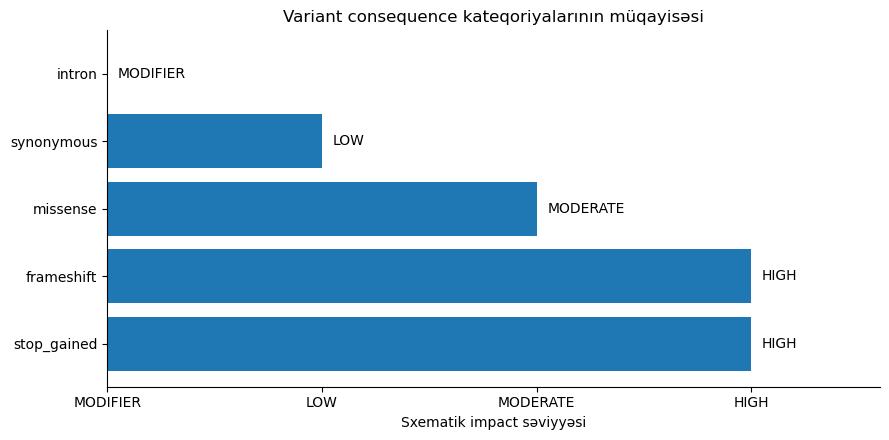

In [8]:
import matplotlib.pyplot as plt

consequences = [
    "stop_gained",
    "frameshift",
    "missense",
    "synonymous",
    "intron"
]

impact_level = [3, 3, 2, 1, 0]

impact_names = {
    3: "HIGH",
    2: "MODERATE",
    1: "LOW",
    0: "MODIFIER"
}

fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.barh(consequences, impact_level)

ax.set_xlim(0, 3.6)
ax.set_xlabel("Sxematik impact səviyyəsi")
ax.set_title("Variant consequence kateqoriyalarının müqayisəsi")
ax.set_xticks([0, 1, 2, 3])
ax.set_xticklabels(["MODIFIER", "LOW", "MODERATE", "HIGH"])

for bar, level in zip(bars, impact_level):
    ax.text(
        level + 0.05,
        bar.get_y() + bar.get_height() / 2,
        impact_names[level],
        va="center"
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

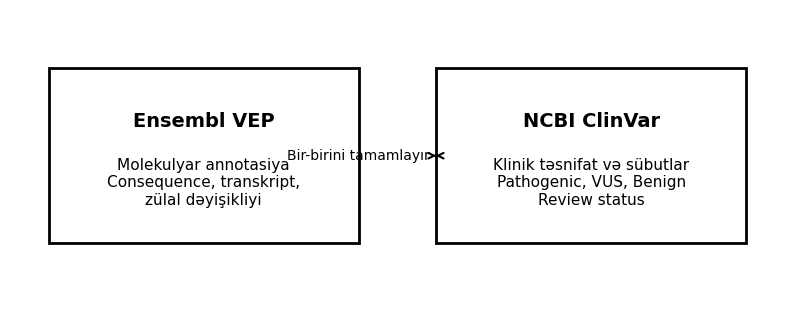

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axis("off")

boxes = [
    (0.05, 0.2, 0.4, 0.6, "Ensembl VEP",
     "Molekulyar annotasiya\nConsequence, transkript,\nzülal dəyişikliyi"),
    (0.55, 0.2, 0.4, 0.6, "NCBI ClinVar",
     "Klinik təsnifat və sübutlar\nPathogenic, VUS, Benign\nReview status")
]

for x, y, w, h, title, description in boxes:
    rect = plt.Rectangle(
        (x, y), w, h,
        fill=False,
        linewidth=2,
        transform=ax.transAxes
    )
    ax.add_patch(rect)
    ax.text(
        x + w / 2, y + h * 0.7, title,
        ha="center", va="center",
        fontsize=14, fontweight="bold",
        transform=ax.transAxes
    )
    ax.text(
        x + w / 2, y + h * 0.35, description,
        ha="center", va="center",
        fontsize=11,
        transform=ax.transAxes
    )

ax.annotate(
    "Bir-birini tamamlayır",
    xy=(0.55, 0.5), xytext=(0.45, 0.5),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center", va="center",
    arrowprops=dict(arrowstyle="<->", linewidth=1.5)
)

plt.show()